# Uber's slide, rebuilt with the one-slide answer and what to leave out: which number carries it?

**Week 4, Tuesday, chapter 4, the case's first chapter.** It applies two of the morning's
topics: the one-slide answer: claim, evidence, caveat, action (concept notebook 01), and
what to leave out, and the appendix (concept notebook 02). On Ramesh's kirana shop
(invented) those notebooks found that the same rupees rose 5.9 percent per day and fell
11.8 percent per hour, that the decision's own unit picks the denominator, and that three of
the draft's eight elements stay on the slide, the caveat among them. This notebook does the
same to Uber's numbers.

**The ticket.** Uber, Hyderabad, the driver app's peak-hour earnings guarantee, one day on.
The city head takes the redesign to the Thursday city review on one slide, in five minutes,
with the driver-operations lead, the marketing lead and the finance partner in the room.
The number the slide must explain first: gross bookings (what riders paid) per peak online
hour fell from Rs 314 in the six weeks before the launch (31 August 2026) to Rs 260 in the
six weeks after, while the average peak fare stayed at Rs 165.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

**What Monday found.** Peak online hours rose 24 percent while completed peak trips rose 3
percent, so trips per peak online hour fell from 1.90 to 1.58, and 61 percent of the Rs 1.9
crore top-up (the gap Uber pays up to the Rs 300 hourly floor) went to driver-weeks that
accepted fewer than half the requests offered to them.

**Who needs the answer.** The city head, whose one slide decides whether the scheme is
kept, ended or changed; a slide that quotes the wrong denominator hands each of the three
roles a number to argue with, and the city keeps paying for idle hours.

**The metric at stake.** Gross bookings per peak online hour, Rs 314 to Rs 260.

**The questions on the way.**

1. What do the twelve rows say when the same rupees are read three ways?
2. Which number could carry the slide, and what does each say over all the driver-weeks?
3. Why does the per-driver-week read rise while the per-hour read falls?
4. Is the fall in rupees per hour all trips, or some of it fare?
5. What does the twelve-week chart look like before and after the makeover?

In [1]:
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, LILAC, PALE, ROSE, AMBER = "#1A0F5C", "#5B3FD6", "#B9AEF0", "#EEEAFB", "#D63A6A", "#C98A00"

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

rows = pd.read_csv("../data/C2_W04_D02_twelve_rows_STUDENT.csv")    # six drivers, two weeks
weeks = pd.read_csv("../data/C2_W04_D02_twelve_weeks_STUDENT.csv")  # the city, week by week
print(len(rows), "driver-weeks in the twelve rows;", len(weeks), "weeks in the city table")
check("twelve driver-weeks and twelve city weeks", len(rows) == 12 and len(weeks) == 12)

12 driver-weeks in the twelve rows; 12 weeks in the city table
PASS twelve driver-weeks and twelve city weeks


## What do the twelve rows say when the same rupees are read three ways?

Each row is one driver in one week (the week of 10 August before the launch, the week of 21
September after it): peak online hours, peak trips and the gross bookings those trips
brought in. Gross bookings are what riders paid for the trips, before Uber's share and
before any top-up. The same rupees can be divided by three things: the hours online, the
driver-weeks, or the trips. The cell sums each column per window and divides three times,
exactly as the board did, then reads each driver's rupees per hour.

**Predict before you run.** The board found Rs 313.5 an hour before and Rs 196.2 after.
Which drivers explain most of that fall?

a) A and B, the two in the busiest central zones
b) C and D, the two who drove the most hours before
c) E and F, Monday's two idle-tail drivers
d) All six about equally

In [2]:
# Sum the twelve rows by window, then divide the same rupees by hours, driver-weeks and trips.
t = rows.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs"]].sum()
t["driver_weeks"] = rows.groupby("window").size()
t["rs_per_hour"] = (t.peak_bookings_rs / t.peak_online_hours).round(1)
t["rs_per_driver_week"] = t.peak_bookings_rs / t.driver_weeks
t["rs_per_trip"] = t.peak_bookings_rs / t.peak_trips
t = t.loc[["before", "after"]]
print(t[["peak_online_hours", "peak_trips", "peak_bookings_rs", "rs_per_hour", "rs_per_driver_week", "rs_per_trip"]])
per_driver = (rows.assign(rs_per_hour=(rows.peak_bookings_rs / rows.peak_online_hours).round(1))
              .pivot(index="driver", columns="window", values="rs_per_hour")[["before", "after"]])
print(per_driver)                                            # rupees per peak online hour, driver by driver
check("hand count: Rs 313.5 and Rs 196.2 per hour", list(t.rs_per_hour) == [313.5, 196.2])
check("hand count: Rs 3,135 and Rs 2,420 per driver-week", list(t.rs_per_driver_week) == [3135, 2420])
check("E and F fall furthest", set(per_driver.after.nsmallest(2).index) == {"E", "F"})

        peak_online_hours  peak_trips  peak_bookings_rs  rs_per_hour  rs_per_driver_week  rs_per_trip
window                                                                                               
before                 60         114             18810        313.5              3135.0        165.0
after                  74          88             14520        196.2              2420.0        165.0
window  before  after
driver               
A        346.5  330.0
B        311.7  297.0
C        330.0  316.2
D        313.5  300.0
E        297.0   30.9
F        280.5   23.6
PASS hand count: Rs 313.5 and Rs 196.2 per hour
PASS hand count: Rs 3,135 and Rs 2,420 per driver-week
PASS E and F fall furthest


**What happened.** The answer is c. E and F fell from Rs 297.0 and Rs 280.5 an hour to Rs
30.9 and Rs 23.6, while A to D stayed near Rs 300 to Rs 330. Per peak online hour the six
drivers fell from Rs 313.5 to Rs 196.2, down 37 percent; per driver-week from Rs 3,135 to
Rs 2,420, down 23 percent; per trip they held at Rs 165, because each trip pays its fare
whatever else happens. Ramesh's shop showed the same thing in notebook 01: three honest
divisions of the same rupees gave three sizes of change, so a slide that says "bookings
fell" without its denominator has said nothing a role cannot argue with.

## Which number could carry the slide, and what does each say over all the driver-weeks?

The city table holds every week's totals. Four numbers could head the slide, and each role
has its favourite:

| Option | What it divides by | Who reaches for it |
|---|---|---|
| Gross peak bookings | nothing: the six weeks' sum | marketing, as "bookings are up" |
| Bookings per peak online hour | the hours the scheme pays for | the analyst |
| Bookings per active driver-week | one enrolled driver with a row that week | driver operations |
| Bookings per completed trip | the trips | finance |

An active driver-week is one enrolled driver with a row in Monday's `driver_weeks` table
that week; a driver with no row that week is not counted. The cell sizes all four on the
city's twelve weeks and draws each one's change.

**Predict before you run.** Rupees per driver-week is rupees per hour times hours per
driver-week. About how many more peak online hours did an average active driver-week carry
after the launch?

a) About 1 more
b) About 4 more
c) About 10 more
d) Fewer than before

        rs_per_hour  rs_per_driver_week  rs_per_trip  hours_per_driver_week
window                                                                     
before        313.5              5816.5        165.0                   18.6
after         260.4              5861.3        165.0                   22.5
peak_bookings_rs          3.0
rs_per_hour             -16.9
rs_per_driver_week        0.8
hours_per_driver_week    21.3
Name: change, percent, dtype: float64
PASS per hour down 16.9 percent, printed as 17
PASS per active driver-week up 0.8 percent
PASS rupees per driver-week is rupees per hour x hours per driver-week


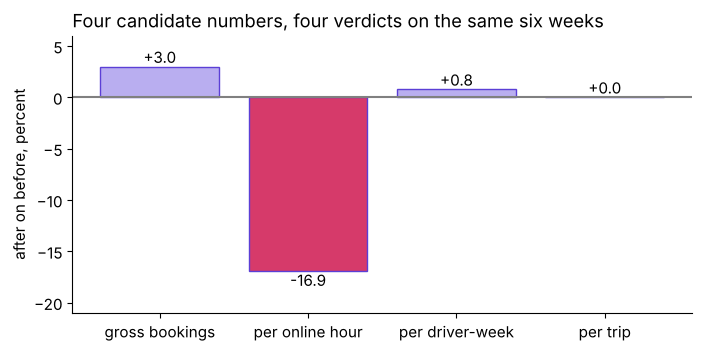

In [3]:
# The four candidate numbers on every driver-week in the city, with hours per driver-week beside them.
w = weeks.groupby("window")[["peak_online_hours", "peak_trips", "peak_bookings_rs", "active_driver_weeks"]].sum()
w = w.loc[["before", "after"]]
w["rs_per_hour"] = w.peak_bookings_rs / w.peak_online_hours
w["rs_per_driver_week"] = w.peak_bookings_rs / w.active_driver_weeks
w["rs_per_trip"] = w.peak_bookings_rs / w.peak_trips
w["hours_per_driver_week"] = w.peak_online_hours / w.active_driver_weeks
change = (w.loc["after"] / w.loc["before"] - 1) * 100
print(w[["rs_per_hour", "rs_per_driver_week", "rs_per_trip", "hours_per_driver_week"]].round(1))
print((change[["peak_bookings_rs", "rs_per_hour", "rs_per_driver_week", "hours_per_driver_week"]]).round(1).rename("change, percent"))
check("per hour down 16.9 percent, printed as 17", round(change.rs_per_hour, 1) == -16.9)
check("per active driver-week up 0.8 percent", round(change.rs_per_driver_week, 1) == 0.8)
check("rupees per driver-week is rupees per hour x hours per driver-week",
      ((w.rs_per_hour * w.hours_per_driver_week - w.rs_per_driver_week).abs() < 1e-6).all())

options = {"gross bookings": change.peak_bookings_rs, "per online hour": change.rs_per_hour,
           "per driver-week": change.rs_per_driver_week, "per trip": change.rs_per_trip}
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(list(options), list(options.values()),
              color=[LILAC, ROSE, LILAC, LILAC], edgecolor=VIOLET)
ax.bar_label(bars, fmt="%+.1f")
ax.axhline(0, color="gray")
ax.set_ylim(-21, 6)
ax.set_ylabel("after on before, percent")
ax.set_title("Four candidate numbers, four verdicts on the same six weeks", loc="left")
plt.show()

**What happened.** The answer is b: 18.6 hours a driver-week before the launch and 22.5
after, up 21 percent. Per peak online hour the rupees fell from Rs 313.5 to Rs 260.4, down
17 percent, and per active driver-week they rose from Rs 5,817 to Rs 5,861, up 0.8 percent,
because the average driver-week carried about four more hours at 17 percent less per hour. Gross
bookings rose 3.0 percent and per trip held at Rs 165.

**The call.** The slide carries bookings per peak online hour, because the scheme pays by
the online hour; the other three go behind it, one per role's question, as notebook 02's
sort sends them. The fact that would change the call: if the scheme paid per completed
trip, per trip would be the number the decision is priced in.

**The plausible wrong answer.** "Bookings per driver-week rose from Rs 5,817 to Rs 5,861, so
the guarantee is working; keep it as it is." That sentence is true to the rupee and would
keep the city paying for idle hours.

**Why it is wrong.** The rise was bought with hours, the very thing the scheme pays for.
Bookings rose 3.0 percent and active driver-weeks 2.2 percent (6,360 to 6,500), so the ratio
rose 0.8 percent. The next cell splits the drivers into those there before the launch and
the 140 who joined after it, to see which group moved the read.

## Is the fall in rupees per hour all trips, or some of it fare?

A second route to the same number: rupees per hour is also the average fare times the trips
each online hour carried. The two routes always agree, since the second splits the first in
two; what the split shows is which half moved.

In [4]:
# Split the city by when drivers joined, then rebuild rupees per hour as fare x trips per hour.
groups = pd.read_csv("../data/C2_W04_D02_driver_groups_STUDENT.csv")  # Monday's rows, split by joined_month
groups["rs_per_driver_week"] = (groups.peak_bookings_rs / groups.driver_weeks).round(0).astype(int)
groups["hours_per_driver_week"] = (groups.peak_online_hours / groups.driver_weeks).round(1)
print(groups[["window", "group", "driver_weeks", "rs_per_driver_week", "hours_per_driver_week"]])
joiner = groups[groups.group == "the 140 joiners"].iloc[0]
check("the joiners sit below the after average, so they pull the read down",
      joiner.rs_per_driver_week < w.loc["after", "rs_per_driver_week"])
fare = w.peak_bookings_rs / w.peak_trips
trips_per_hour = w.peak_trips / w.peak_online_hours
second_route = fare * trips_per_hour
print(pd.DataFrame({"fare": fare, "trips_per_hour": trips_per_hour.round(3),
                    "fare_x_trips_per_hour": second_route.round(1)}))
check("second route agrees with bookings / hours in both windows",
      ((second_route - w.rs_per_hour).abs() < 1e-9).all())

   window                            group  driver_weeks  rs_per_driver_week  hours_per_driver_week
0  before  drivers there before the launch          6360                5817                   18.6
1   after  drivers there before the launch          6360                5895                   22.6
2   after                  the 140 joiners           140                4314                   16.4
PASS the joiners sit below the after average, so they pull the read down
         fare  trips_per_hour  fare_x_trips_per_hour
window                                              
before  165.0           1.900                  313.5
after   165.0           1.578                  260.4
PASS second route agrees with bookings / hours in both windows


**What happened.** The 1,060 drivers who were there before the launch rose from Rs 5,816.5 to
Rs 5,895.4 a driver-week, up 1.4 percent, on 22.6 hours a week against 18.6. The 140 joiners
drove about one week each at Rs 4,314, below the average, so they pulled the read down to
0.8 percent. The fare held at Rs 165 in both windows, and trips per hour fell from 1.900 to
1.578 (printed elsewhere as 1.58): Rs 165 x 1.578 is Rs 260.4, so the whole fall in rupees
per hour is the fall in trips per hour Monday found. That is the evidence line the slide
stands on when the finance partner asks whether riders paid less.

## What does the twelve-week chart look like before and after the makeover?

The cluttered version is the one dashboards send: four series in four units on one axis, two
of them divided by 20 or 100 to fit, a legend away from the lines, gridlines, and a title
that names a topic. The clear version keeps one series, bookings per peak online hour,
because the scheme pays by the online hour; it draws the launch, labels the two windows'
values on the lines, and makes the title a sentence, the claim of notebook 01's first part.

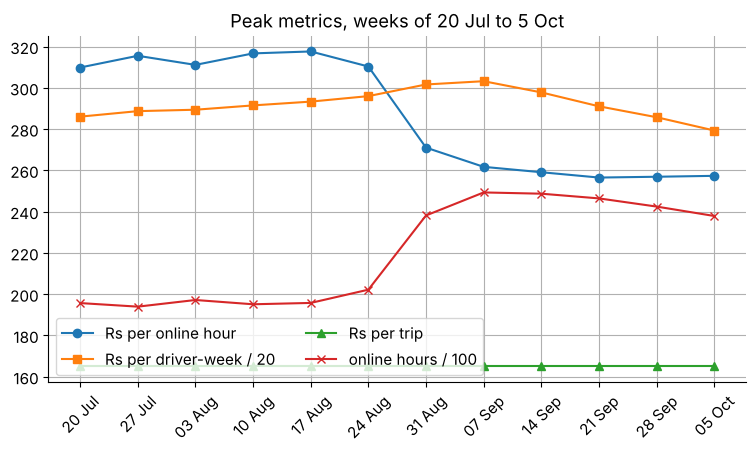

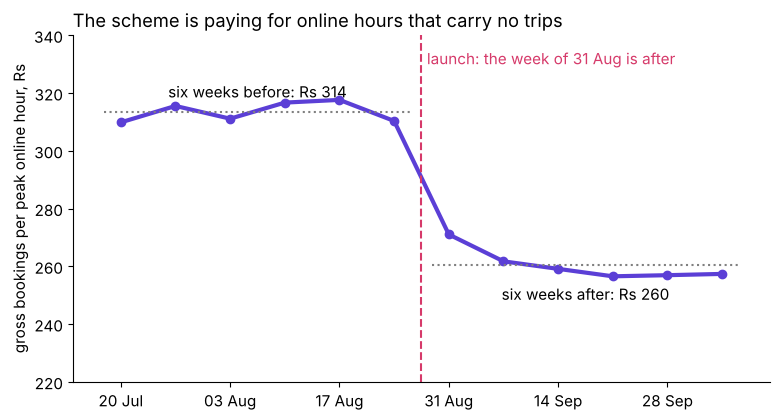

PASS every after week sits below every before week: a step at the launch, not a slow drift


In [5]:
# Draw the series cluttered, then the makeover: one series, the launch, two labels, a sentence title.
x = range(len(weeks))
labels = pd.to_datetime(weeks.week_start).dt.strftime("%d %b")

fig, ax = plt.subplots(figsize=(9, 4.5))                      # before: everything at once
ax.plot(x, weeks.rs_per_hour, marker="o", label="Rs per online hour")
ax.plot(x, weeks.rs_per_driver_week / 20, marker="s", label="Rs per driver-week / 20")
ax.plot(x, weeks.rs_per_trip, marker="^", label="Rs per trip")
ax.plot(x, weeks.peak_online_hours / 100, marker="x", label="online hours / 100")
ax.grid(True); ax.legend(loc="lower left", ncol=2)
ax.set_xticks(list(x), labels, rotation=45); ax.set_title("Peak metrics, weeks of 20 Jul to 5 Oct")
plt.show()

before, after = w.rs_per_hour
fig, ax = plt.subplots(figsize=(9, 4.5))                      # after: one claim, one series
ax.plot(x, weeks.rs_per_hour, color=VIOLET, lw=3, marker="o")
ax.hlines(before, -0.3, 5.3, color="gray", ls=":"); ax.hlines(after, 5.7, 11.3, color="gray", ls=":")
ax.text(2.5, before + 5, f"six weeks before: Rs {before:.0f}", ha="center")
ax.text(8.5, after - 12, f"six weeks after: Rs {after:.0f}", ha="center")
ax.axvline(5.5, color=ROSE, ls="--")
ax.text(5.6, 330, "launch: the week of 31 Aug is after", color=ROSE)
ax.set_ylim(220, 340); ax.set_xticks(list(x)[::2], labels[::2])
ax.set_title("The scheme is paying for online hours that carry no trips", loc="left")
ax.set_ylabel("gross bookings per peak online hour, Rs")
plt.show()
step = weeks[weeks.window == "after"].rs_per_hour.max() < weeks[weeks.window == "before"].rs_per_hour.min()
check("every after week sits below every before week: a step at the launch, not a slow drift", step)

**What happened.** On the clear chart the eye finds the claim in a second: about Rs 314 an
hour before, about Rs 260 after, and the drop lands in the launch week, with the highest
after week (Rs 271) below the lowest before week (Rs 310). A season that ended slowly would
drift; this steps. That helps with the finance partner's monsoon objection without settling
it, since last year's weeks are not in the data, and chapter 5's notebook takes the
objection up.

**The answers, one line each.**

1. On the twelve rows the same rupees fell 37 percent per hour, 23 percent per driver-week
   and 0 per trip, and E and F explain most of the fall.
2. Over all driver-weeks, gross bookings rose 3.0 percent, per hour fell 17 percent, per
   active driver-week rose 0.8 percent and per trip held; the slide carries per hour.
3. The average driver-week carried about four more hours, and the 140 joiners pulled the
   read down.
4. The fall is all trips: Rs 165 x 1.90 is Rs 313.5, and Rs 165 x 1.578 is Rs 260.4.
5. The clear chart carries one series, a launch line and a sentence for a title; the drop
   is a step at the launch.

### What will an interviewer ask about this, and what does a strong answer do?

**[S] Present this recommendation to a non-technical leader in two minutes.** Name the
decision, open on the claim ("the scheme is paying for online hours that carry no trips"),
give one number with its denominator (Rs 314 to Rs 260 per peak online hour), say what
riders got (a median wait of 4.8 to 4.6 minutes), say the caveat (the monsoon ended inside
the six weeks), and end on the action with its cost and signer (test paying per completed
peak trip with an acceptance floor; across the enrolled drivers it saves Rs 58 lakh to Rs
92.7 lakh over six weeks if a half to a fifth of the idle drivers' top-up is still paid, and
the per-trip rate can move it within that range or beyond it; the city head signs the test).

**The AI-company variant.** A coding assistant's dashboard reports suggestions accepted per
developer-week. The same trap waits: accepted text can be deleted soon after, and a developer
who gives up on the tool drops out of a per-developer read. A read that matches what the
customer pays for is suggested code still in the file seven days after acceptance, per paid
seat a week, with characters per accepted suggestion as the guardrail against padding and
acceptance kept as a leading input.